# Demo thực nghiệm: Word2Vec, GloVe, FastText

Notebook đi kèm file Word *Text Representation and Embedding Techniques in NLP – Phần 2*. Notebook viết để chạy trên **Google Colab** (cần Internet để tải dữ liệu và mô hình).

**Nội dung**
0. Cài đặt và cấu hình
1. Dữ liệu huấn luyện (text8)
2. Word2Vec: CBOW và Skip-gram
3. GloVe: tự cài đặt mini từ đầu (numpy) và dùng vector huấn luyện sẵn
4. FastText: n-gram ký tự và xử lý từ ngoài từ điển (OOV)
5. Đánh giá định lượng: analogy và độ tương đồng từ
6. Trực quan hóa vector bằng PCA
7. Demo nhỏ với tiếng Việt
8. Nhận xét

> Lưu ý: kết quả cụ thể (từ gần nhất, điểm số, thời gian chạy) phụ thuộc phiên bản thư viện, seed và cấu hình máy, nên có thể khác một chút giữa các lần chạy.

## 0. Cài đặt và cấu hình

In [1]:
!pip install -q gensim matplotlib scikit-learn pandas
# Nếu Colab báo lỗi tương thích numpy sau khi cài: Runtime -> Restart session rồi chạy lại từ đầu.

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gensim
import gensim.downloader as api
from gensim.models import Word2Vec, FastText, KeyedVectors
from gensim.models.word2vec import Text8Corpus
from gensim.test.utils import datapath

print("gensim:", gensim.__version__)

# ---- cấu hình chung ----
N_SENT  = 600   # số "câu" text8 dùng để huấn luyện (mỗi câu ~10.000 từ). Tối đa 1701 (toàn bộ, chậm hơn)
DIM     = 100   # số chiều vector
WINDOW  = 5     # kích thước cửa sổ ngữ cảnh
MIN_CNT = 5     # bỏ từ xuất hiện ít hơn MIN_CNT lần
EPOCHS  = 5
WORKERS = 4
SEED    = 42

gensim: 4.4.0


## 1. Dữ liệu huấn luyện

Dùng **text8**: khoảng 17 triệu từ lấy từ Wikipedia tiếng Anh, đã chuyển chữ thường và bỏ dấu câu. Đây là tập dữ liệu nhỏ phổ biến để thử Word2Vec.

In [3]:
# Lấy đường dẫn file text8 rồi tự đọc bằng Text8Corpus.
# (Không dùng api.load("text8") trực tiếp vì loader đi kèm gói dữ liệu có thể lỗi
#  "cannot import name 'smart_open'" với smart_open bản mới.)
text8_path = api.load("text8", return_path=True)
text8 = list(Text8Corpus(text8_path))     # danh sách các câu; mỗi câu là một list từ
corpus = text8[:N_SENT]

n_tokens = sum(len(s) for s in corpus)
print("Số câu:", len(corpus), "| Số từ:", f"{n_tokens:,}")
print("10 từ đầu:", corpus[0][:10])

[==================================================] 100.0% 31.6/31.6MB downloaded
Số câu: 600 | Số từ: 6,000,000
10 từ đầu: ['anarchism', 'originated', 'as', 'a', 'term', 'of', 'abuse', 'first', 'used', 'against']


## 2. Word2Vec: CBOW và Skip-gram

- **CBOW** (`sg=0`): dùng các từ ngữ cảnh để dự đoán từ đích.
- **Skip-gram** (`sg=1`): dùng từ đích để dự đoán các từ ngữ cảnh.

In [4]:
def train_w2v(sg):
    t0 = time.time()
    model = Word2Vec(corpus, vector_size=DIM, window=WINDOW, min_count=MIN_CNT,
                     sg=sg, workers=WORKERS, epochs=EPOCHS, seed=SEED)
    return model, time.time() - t0

w2v_cbow, t_cbow = train_w2v(sg=0)
w2v_sg,   t_sg   = train_w2v(sg=1)

print(f"CBOW     : {t_cbow:6.1f}s | từ điển {len(w2v_cbow.wv):,} từ")
print(f"Skip-gram: {t_sg:6.1f}s | từ điển {len(w2v_sg.wv):,} từ")

CBOW     :   65.6s | từ điển 40,294 từ
Skip-gram:  180.6s | từ điển 40,294 từ


In [5]:
for name, m in [("CBOW", w2v_cbow), ("Skip-gram", w2v_sg)]:
    print(f"=== {name} ===")
    print("Gần 'king'   :", [(w, round(s, 2)) for w, s in m.wv.most_similar("king", topn=5)])
    print("Gần 'france' :", [(w, round(s, 2)) for w, s in m.wv.most_similar("france", topn=5)])
    print("similarity(king, queen) =", round(float(m.wv.similarity("king", "queen")), 3))
    print("similarity(king, car)   =", round(float(m.wv.similarity("king", "car")), 3))
    print("Từ lạc loài trong [breakfast, lunch, dinner, car]:", m.wv.doesnt_match(["breakfast", "lunch", "dinner", "car"]))
    print()

=== CBOW ===
Gần 'king'   : [('emperor', 0.87), ('throne', 0.84), ('constantine', 0.83), ('judah', 0.82), ('son', 0.81)]
Gần 'france' : [('spain', 0.87), ('italy', 0.84), ('germany', 0.79), ('portugal', 0.78), ('austria', 0.76)]
similarity(king, queen) = 0.779
similarity(king, car)   = -0.077
Từ lạc loài trong [breakfast, lunch, dinner, car]: car

=== Skip-gram ===
Gần 'king'   : [('throne', 0.76), ('darius', 0.76), ('judah', 0.76), ('vii', 0.75), ('macedon', 0.75)]
Gần 'france' : [('spain', 0.8), ('italy', 0.8), ('netherlands', 0.74), ('portugal', 0.71), ('norway', 0.7)]
similarity(king, queen) = 0.678
similarity(king, car)   = 0.107
Từ lạc loài trong [breakfast, lunch, dinner, car]: car



In [6]:
# Phép tính vector (analogy): king - man + woman ≈ ?   |   paris - france + italy ≈ ?
def analogy(kv, pos, neg, topn=3):
    try:
        return [(w, round(s, 2)) for w, s in kv.most_similar(positive=pos, negative=neg, topn=topn)]
    except KeyError as e:
        return f"thiếu từ trong từ điển: {e}"

for name, m in [("CBOW", w2v_cbow), ("Skip-gram", w2v_sg)]:
    print(f"=== {name} ===")
    print("king - man + woman   ->", analogy(m.wv, ["king", "woman"], ["man"]))
    print("paris - france + italy ->", analogy(m.wv, ["paris", "italy"], ["france"]))

=== CBOW ===
king - man + woman   -> [('consul', 0.78), ('emperor', 0.75), ('son', 0.74)]
paris - france + italy -> [('vienna', 0.79), ('philadelphia', 0.79), ('venice', 0.75)]
=== Skip-gram ===
king - man + woman   -> [('throne', 0.67), ('queen', 0.64), ('consort', 0.64)]
paris - france + italy -> [('bologna', 0.7), ('florence', 0.67), ('naples', 0.67)]


## 3. GloVe

### 3.1. Tự cài đặt GloVe mini bằng numpy

Các bước: (1) xây **ma trận đồng xuất hiện X** trên một kho nhỏ; (2) học vector sao cho `w_i · w'_j + b_i + b'_j ≈ log X_ij` bằng hàm mục tiêu bình phương tối thiểu có trọng số `f(X_ij)`, tối ưu bằng AdaGrad.

Kho văn bản chỉ có vài câu đơn giản nên kết quả chỉ mang tính minh họa cơ chế.

In [7]:
corpus_mini = [
    "the king rules the kingdom",
    "the queen rules the kingdom",
    "the king loves the queen",
    "the queen loves the king",
    "the man works in the city",
    "the woman works in the city",
    "the man loves the woman",
    "the woman loves the man",
    "a prince is a young king",
    "a princess is a young queen",
    "a boy is a young man",
    "a girl is a young woman",
]
tok = [s.split() for s in corpus_mini]
vocab = sorted({w for s in tok for w in s})
w2i = {w: i for i, w in enumerate(vocab)}
V = len(vocab)

# --- ma trận đồng xuất hiện, cửa sổ 2, trọng số 1/khoảng cách ---
WIN = 2
X = np.zeros((V, V))
for s in tok:
    ids = [w2i[w] for w in s]
    for p, i in enumerate(ids):
        for off in range(1, WIN + 1):
            if p + off < len(ids):
                j = ids[p + off]
                X[i, j] += 1.0 / off
                X[j, i] += 1.0 / off

print("Kích thước từ điển:", V, "| số cặp đồng xuất hiện khác 0:", int((X > 0).sum()))
print(pd.DataFrame(X, index=vocab, columns=vocab).loc[["king", "queen", "man", "woman"], ["rules", "loves", "kingdom", "city", "young"]])

Kích thước từ điển: 18 | số cặp đồng xuất hiện khác 0: 84
       rules  loves  kingdom  city  young
king     1.0    1.5      0.0   0.0    1.0
queen    1.0    1.5      0.0   0.0    1.0
man      0.0    1.5      0.0   0.0    1.0
woman    0.0    1.5      0.0   0.0    1.0


In [8]:
def train_glove(X, dim=10, x_max=10.0, alpha=0.75, lr=0.05, epochs=300, seed=42, verbose=True):
    rng = np.random.default_rng(seed)
    V = X.shape[0]
    W  = (rng.random((V, dim)) - 0.5) / dim      # vector từ
    Wc = (rng.random((V, dim)) - 0.5) / dim      # vector ngữ cảnh
    b, bc = np.zeros(V), np.zeros(V)
    gW, gWc = np.ones((V, dim)), np.ones((V, dim))   # bộ tích lũy AdaGrad
    gb, gbc = np.ones(V), np.ones(V)
    pairs = np.argwhere(X > 0)
    f = lambda x: np.minimum((x / x_max) ** alpha, 1.0)

    for ep in range(epochs):
        rng.shuffle(pairs)
        loss = 0.0
        for i, j in pairs:
            x = X[i, j]
            diff = W[i] @ Wc[j] + b[i] + bc[j] - np.log(x)
            fx = f(x)
            loss += 0.5 * fx * diff ** 2
            g = fx * diff
            dW, dWc = g * Wc[j], g * W[i]
            W[i]   -= lr * dW  / np.sqrt(gW[i])
            Wc[j]  -= lr * dWc / np.sqrt(gWc[j])
            b[i]   -= lr * g   / np.sqrt(gb[i])
            bc[j]  -= lr * g   / np.sqrt(gbc[j])
            gW[i] += dW ** 2;  gWc[j] += dWc ** 2
            gb[i] += g ** 2;   gbc[j] += g ** 2
        if verbose and (ep % 50 == 0 or ep == epochs - 1):
            print(f"epoch {ep:3d}  loss = {loss:.4f}")
    return W + Wc          # vector cuối cùng = tổng vector từ và vector ngữ cảnh

E = train_glove(X)

epoch   0  loss = 9.6960
epoch  50  loss = 1.6888
epoch 100  loss = 0.5477
epoch 150  loss = 0.1186
epoch 200  loss = 0.0275
epoch 250  loss = 0.0094
epoch 299  loss = 0.0047


In [9]:
def cos(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

def nearest(word, topn=4):
    v = E[w2i[word]]
    sims = [(w, cos(v, E[w2i[w]])) for w in vocab if w != word]
    return [(w, round(s, 2)) for w, s in sorted(sims, key=lambda x: -x[1])[:topn]]

for w in ["king", "queen", "man", "woman"]:
    print(f"{w:6s} ->", nearest(w))

print()
print("cos(king, queen) =", round(cos(E[w2i['king']], E[w2i['queen']]), 3))
print("cos(king, city)  =", round(cos(E[w2i['king']], E[w2i['city']]), 3))

king   -> [('queen', 1.0), ('man', 0.99), ('woman', 0.98), ('the', 0.85)]
queen  -> [('king', 1.0), ('man', 0.99), ('woman', 0.99), ('the', 0.86)]
man    -> [('queen', 0.99), ('woman', 0.99), ('king', 0.99), ('the', 0.84)]
woman  -> [('man', 0.99), ('queen', 0.99), ('king', 0.98), ('the', 0.85)]

cos(king, queen) = 0.997
cos(king, city)  = -0.855


### 3.2. Dùng vector GloVe huấn luyện sẵn

Bộ `glove-wiki-gigaword-100`: vector 100 chiều, huấn luyện trên Wikipedia 2014 và Gigaword 5 (khoảng 6 tỷ từ), tức nhiều dữ liệu hơn rất nhiều so với text8 ở phần trên (tải khoảng 130 MB).

In [10]:
try:
    glove = api.load("glove-wiki-gigaword-100")      # KeyedVectors
except ImportError:                                  # dự phòng: tự nạp từ file đã tải
    glove_path = api.load("glove-wiki-gigaword-100", return_path=True)
    glove = KeyedVectors.load_word2vec_format(glove_path)
print("Số từ trong từ điển:", len(glove))

print("Gần 'king'   :", [(w, round(s, 2)) for w, s in glove.most_similar("king", topn=5)])
print("Gần 'france' :", [(w, round(s, 2)) for w, s in glove.most_similar("france", topn=5)])
print("king - man + woman     ->", analogy(glove, ["king", "woman"], ["man"]))
print("paris - france + italy ->", analogy(glove, ["paris", "italy"], ["france"]))

[==================================================] 100.0% 128.1/128.1MB downloaded
Số từ trong từ điển: 400000
Gần 'king'   : [('prince', 0.77), ('queen', 0.75), ('son', 0.7), ('brother', 0.7), ('monarch', 0.7)]
Gần 'france' : [('belgium', 0.81), ('french', 0.8), ('britain', 0.8), ('spain', 0.76), ('paris', 0.75)]
king - man + woman     -> [('queen', 0.77), ('monarch', 0.68), ('throne', 0.68)]
paris - france + italy -> [('rome', 0.82), ('milan', 0.74), ('naples', 0.71)]


## 4. FastText

FastText biểu diễn mỗi từ bằng **túi các n-gram ký tự** và lấy vector của từ bằng tổng vector các n-gram, nên vẫn tạo được vector cho từ **chưa có trong từ điển (OOV)**.

### 4.1. N-gram ký tự

In [11]:
def char_ngrams(word, n_min=3, n_max=6):
    w = f"<{word}>"                                   # thêm ký hiệu biên < >
    grams = [w[i:i + n] for n in range(n_min, n_max + 1) for i in range(len(w) - n + 1)]
    return grams + [w]                                # FastText còn thêm cả từ nguyên vẹn

print("n=3 cho 'where':", char_ngrams("where", 3, 3))
print("n=3..6 cho 'where':", char_ngrams("where", 3, 6))
print("Số n-gram của 'running':", len(char_ngrams("running")))

n=3 cho 'where': ['<wh', 'whe', 'her', 'ere', 're>', '<where>']
n=3..6 cho 'where': ['<wh', 'whe', 'her', 'ere', 're>', '<whe', 'wher', 'here', 'ere>', '<wher', 'where', 'here>', '<where', 'where>', '<where>']
Số n-gram của 'running': 23


### 4.2. Huấn luyện FastText trên cùng kho text8

In [12]:
t0 = time.time()
ft = FastText(corpus, vector_size=DIM, window=WINDOW, min_count=MIN_CNT, min_n=3, max_n=6,
              sg=1, workers=WORKERS, epochs=EPOCHS, seed=SEED)
t_ft = time.time() - t0
print(f"FastText: {t_ft:.1f}s | từ điển {len(ft.wv):,} từ")

FastText: 370.2s | từ điển 40,294 từ


In [13]:
# So sánh xử lý từ ngoài từ điển (OOV): Word2Vec báo lỗi, FastText vẫn tạo được vector
oov_words = ["kingg", "computerization", "unbelievably"]

for w in oov_words:
    in_vocab_w2v = w in w2v_sg.wv.key_to_index
    in_vocab_ft  = w in ft.wv.key_to_index
    print(f"\n'{w}': trong từ điển Word2Vec? {in_vocab_w2v} | trong từ điển FastText? {in_vocab_ft}")

    try:
        w2v_sg.wv[w]
        print("  Word2Vec : có vector")
    except KeyError:
        print("  Word2Vec : KeyError (không có vector)")

    vec = ft.wv[w]                                    # FastText ghép vector từ các n-gram
    near = ft.wv.similar_by_vector(vec, topn=4)
    print("  FastText : có vector, gần nhất ->", [(x, round(s, 2)) for x, s in near])


'kingg': trong từ điển Word2Vec? False | trong từ điển FastText? False
  Word2Vec : KeyError (không có vector)
  FastText : có vector, gần nhất -> [('kingpin', 0.85), ('king', 0.85), ('kingsley', 0.82), ('kingship', 0.82)]

'computerization': trong từ điển Word2Vec? False | trong từ điển FastText? False
  Word2Vec : KeyError (không có vector)
  FastText : có vector, gần nhất -> [('optimization', 0.89), ('computation', 0.88), ('rasterization', 0.87), ('visualization', 0.87)]

'unbelievably': trong từ điển Word2Vec? False | trong từ điển FastText? False
  Word2Vec : KeyError (không có vector)
  FastText : có vector, gần nhất -> [('believable', 0.89), ('conceivably', 0.84), ('inexplicably', 0.83), ('unjustly', 0.83)]


In [14]:
# Từ cùng gốc/biến thể hình thái: độ tương đồng cosine giữa các dạng của một từ
pairs = [("run", "running"), ("king", "kings"), ("quick", "quickly"), ("king", "car")]
rows = []
for a, b in pairs:
    rows.append({
        "cặp từ": f"{a} - {b}",
        "Word2Vec (Skip-gram)": round(float(w2v_sg.wv.similarity(a, b)), 3) if a in w2v_sg.wv.key_to_index and b in w2v_sg.wv.key_to_index else None,
        "FastText": round(float(ft.wv.similarity(a, b)), 3),
    })
pd.DataFrame(rows)

,cặp từ,Word2Vec (Skip-gram),FastText
0,run - running,0.737,0.757
1,king - kings,0.720,0.684
2,quick - quickly,0.601,0.762
3,king - car,0.107,0.241


## 5. Đánh giá định lượng

Dùng hai bộ kiểm tra có sẵn trong gensim:
- **Analogy** (`questions-words.txt`, ~19.5 nghìn câu kiểu *man : king :: woman : ?*): đo tỉ lệ trả lời đúng.
- **WordSim353** (`wordsim353.tsv`): tương quan Spearman giữa độ tương đồng do mô hình tính và điểm do con người chấm.

> GloVe huấn luyện sẵn dùng nhiều dữ liệu hơn hẳn (6 tỷ từ so với khoảng 6 triệu từ), nên **không so sánh công bằng** với ba mô hình huấn luyện trên text8. Để so sánh công bằng giữa các kỹ thuật, nên nhìn ba dòng CBOW, Skip-gram, FastText.

In [15]:
def evaluate(name, kv):
    acc, _ = kv.evaluate_word_analogies(datapath("questions-words.txt"))
    (_, _), (spearman, _), oov = kv.evaluate_word_pairs(datapath("wordsim353.tsv"))
    return {"Mô hình": name,
            "Analogy (tỉ lệ đúng)": round(acc, 3),
            "WordSim353 (Spearman)": round(spearman, 3),
            "OOV cặp từ (%)": round(oov, 1)}

results = pd.DataFrame([
    evaluate("Word2Vec - CBOW (text8)", w2v_cbow.wv),
    evaluate("Word2Vec - Skip-gram (text8)", w2v_sg.wv),
    evaluate("FastText (text8)", ft.wv),
    evaluate("GloVe huấn luyện sẵn (6B từ)", glove),
])
results

,Mô hình,Analogy (tỉ lệ đúng),WordSim353 (Spearman),OOV cặp từ (%)
0,Word2Vec - CBOW (text8),0.109,0.532,3.1
1,Word2Vec - Skip-gram (text8),0.160,0.627,3.1
2,FastText (text8),0.442,0.542,3.1
3,GloVe huấn luyện sẵn (6B từ),0.633,0.533,0.0


In [16]:
times = pd.DataFrame({"Mô hình": ["CBOW", "Skip-gram", "FastText"],
                      "Thời gian huấn luyện (giây)": [round(t_cbow, 1), round(t_sg, 1), round(t_ft, 1)]})
times

,Mô hình,Thời gian huấn luyện (giây)
0,CBOW,65.6
1,Skip-gram,180.6
2,FastText,370.2


## 6. Trực quan hóa vector bằng PCA

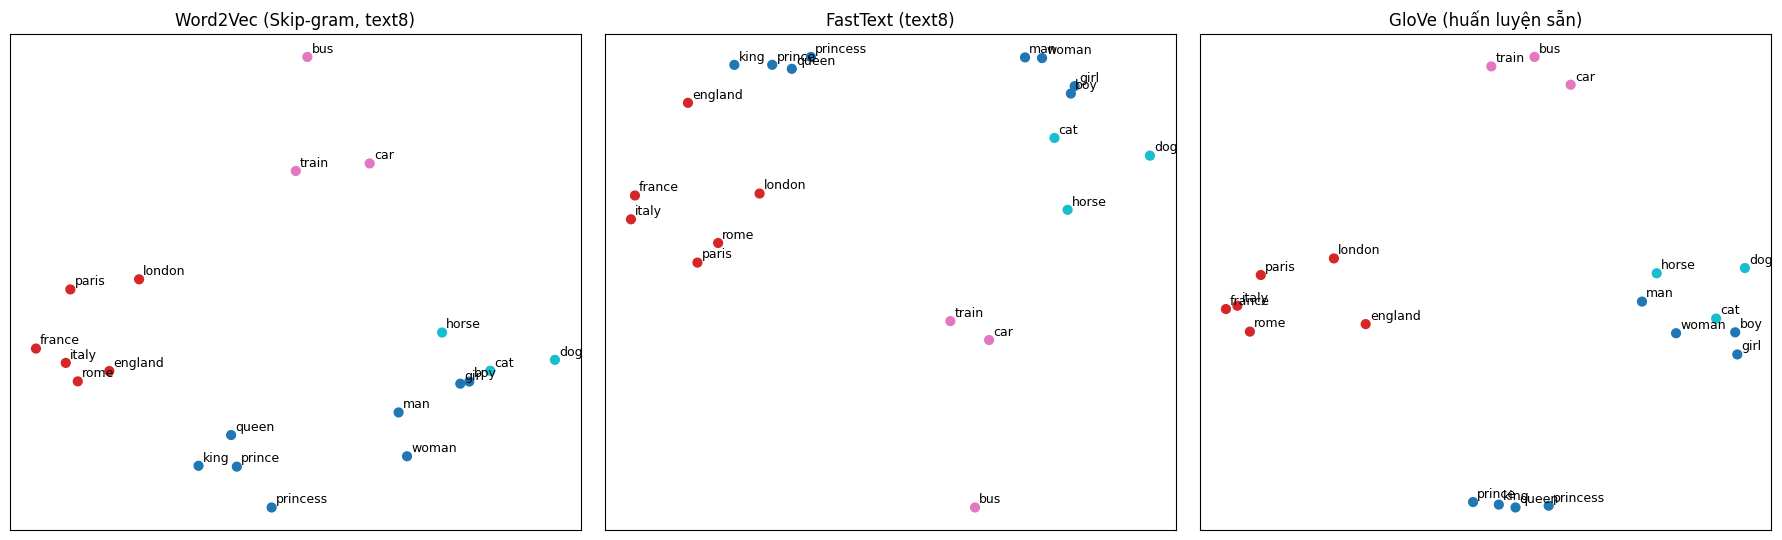

In [17]:
from sklearn.decomposition import PCA

words = ["king", "queen", "prince", "princess", "man", "woman", "boy", "girl",
         "paris", "france", "london", "england", "rome", "italy",
         "car", "bus", "train", "dog", "cat", "horse"]
groups = {  # nhóm để tô màu
    "hoàng gia / giới": ["king", "queen", "prince", "princess", "man", "woman", "boy", "girl"],
    "thủ đô / quốc gia": ["paris", "france", "london", "england", "rome", "italy"],
    "phương tiện": ["car", "bus", "train"],
    "động vật": ["dog", "cat", "horse"],
}
color_of = {w: i for i, ws in enumerate(groups.values()) for w in ws}

def plot_pca(kv, title, ax):
    ws = [w for w in words if w in kv.key_to_index]
    pts = PCA(n_components=2, random_state=SEED).fit_transform(np.array([kv[w] for w in ws]))
    ax.scatter(pts[:, 0], pts[:, 1], c=[color_of[w] for w in ws], cmap="tab10", s=40)
    for (x, y), w in zip(pts, ws):
        ax.annotate(w, (x, y), fontsize=9, xytext=(3, 3), textcoords="offset points")
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
plot_pca(w2v_sg.wv, "Word2Vec (Skip-gram, text8)", axes[0])
plot_pca(ft.wv, "FastText (text8)", axes[1])
plot_pca(glove, "GloVe (huấn luyện sẵn)", axes[2])
plt.tight_layout()
plt.show()

## 7. Demo nhỏ với tiếng Việt

Kho tiếng Việt dưới đây **rất nhỏ** (chỉ để minh họa cơ chế), văn bản đã được **tách từ** sẵn (từ ghép nối bằng dấu gạch dưới). Với kho nhỏ như vậy, chất lượng vector không đáng tin; điểm cần quan sát là FastText vẫn tạo vector cho từ viết sai hoặc viết không dấu nhờ n-gram ký tự, còn Word2Vec thì không.

In [18]:
corpus_vi = [
    "sinh_viên học xử_lý ngôn_ngữ tự_nhiên",
    "sinh_viên học máy và học sâu",
    "giảng_viên dạy xử_lý ngôn_ngữ tự_nhiên",
    "giảng_viên dạy học máy",
    "sinh_viên làm bài_tập về xử_lý ngôn_ngữ",
    "sinh_viên làm đồ_án học sâu",
    "trường đại_học tổ_chức hội_thảo về trí_tuệ nhân_tạo",
    "sinh_viên tham_gia hội_thảo về trí_tuệ nhân_tạo",
    "giảng_viên hướng_dẫn sinh_viên làm đồ_án",
    "giảng_viên hướng_dẫn sinh_viên làm bài_tập",
] * 20                                          # lặp lại để mô hình có đủ bước cập nhật
sent_vi = [s.split() for s in corpus_vi]

w2v_vi = Word2Vec(sent_vi, vector_size=50, window=3, min_count=1, sg=1, epochs=50, seed=SEED, workers=1)
ft_vi  = FastText(sent_vi, vector_size=50, window=3, min_count=1, min_n=3, max_n=6, sg=1, epochs=50, seed=SEED, workers=1)

print("Từ điển:", len(w2v_vi.wv), "từ")
for w in ["sinh_vien", "sinh_viên"]:                # 'sinh_vien' là bản viết không dấu (OOV)
    in_w2v = w in w2v_vi.wv.key_to_index
    print(f"'{w}' trong từ điển? {in_w2v}")

Từ điển: 22 từ
'sinh_vien' trong từ điển? False
'sinh_viên' trong từ điển? True


In [19]:
oov_vi = "sinh_vien"       # viết không dấu, chưa có trong từ điển
try:
    w2v_vi.wv[oov_vi]
except KeyError:
    print("Word2Vec : KeyError, không có vector cho", oov_vi)

v = ft_vi.wv[oov_vi]
near = ft_vi.wv.similar_by_vector(v, topn=3)
print("FastText : có vector cho", oov_vi, "| gần nhất ->", [(x, round(s, 2)) for x, s in near])
print("cos(sinh_vien, sinh_viên) =", round(float(ft_vi.wv.similarity(oov_vi, "sinh_viên")), 3))
print("cos(sinh_vien, giảng_viên) =", round(float(ft_vi.wv.similarity(oov_vi, "giảng_viên")), 3))

Word2Vec : KeyError, không có vector cho sinh_vien
FastText : có vector cho sinh_vien | gần nhất -> [('sinh_viên', 1.0), ('hướng_dẫn', 1.0), ('giảng_viên', 1.0)]
cos(sinh_vien, sinh_viên) = 1.0
cos(sinh_vien, giảng_viên) = 0.999


## 8. Nhận xét

- **Word2Vec:** huấn luyện nhanh, học được quan hệ ngữ nghĩa (từ gần nghĩa, analogy). CBOW thường nhanh hơn, Skip-gram thường tốt hơn với từ ít gặp. Không có vector cho từ ngoài từ điển.
- **GloVe:** dựa trên ma trận đồng xuất hiện toàn cục; phần tự cài đặt cho thấy cơ chế học vector từ log của số lần đồng xuất hiện. Bộ vector huấn luyện sẵn rất tiện dùng ngay, chất lượng tốt nhờ lượng dữ liệu lớn.
- **FastText:** chậm và nặng hơn do phải học vector cho nhiều n-gram, nhưng tạo được vector cho từ hiếm, từ viết sai và biến thể hình thái; hữu ích với ngôn ngữ giàu hình thái và dữ liệu nhỏ.
- **Hạn chế chung:** cả ba đều là embedding tĩnh, mỗi từ chỉ có một vector nên không phân biệt được các nghĩa khác nhau của từ đa nghĩa; đây là lý do ra đời các embedding theo ngữ cảnh (ELMo, BERT…).
- **Tiếng Việt:** cần tách từ trước khi huấn luyện Word2Vec/GloVe; FastText có lợi thế khi dữ liệu có lỗi gõ hoặc viết không dấu.